In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [19]:
df = pd.read_csv(
    "student-mat.csv",
    sep=None,
    engine="python"
)

print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (395, 33)
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]


In [20]:
print(df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print(df.describe())

0
Duplicate Rows: 0
              age        Medu        Fedu  traveltime   studytime    failures  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean    16.696203    2.749367    2.521519    1.448101    2.035443    0.334177   
std      1.276043    1.094735    1.088201    0.697505    0.839240    0.743651   
min     15.000000    0.000000    0.000000    1.000000    1.000000    0.000000   
25%     16.000000    2.000000    2.000000    1.000000    1.000000    0.000000   
50%     17.000000    3.000000    2.000000    1.000000    2.000000    0.000000   
75%     18.000000    4.000000    3.000000    2.000000    2.000000    0.000000   
max     22.000000    4.000000    4.000000    4.000000    4.000000    3.000000   

           famrel    freetime       goout        Dalc        Walc      health  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean     3.944304    3.235443    3.108861    1.481013    2.291139    3.554430   
std    

In [21]:
print("Missing Values:")
print(df.isnull().sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Dataset Shape After Cleaning:", df.shape)

Missing Values:
0
Duplicate Rows: 0
Dataset Shape After Cleaning: (395, 33)


In [23]:
numeric_cols = df.select_dtypes(include=np.number).columns

df[numeric_cols] = df[numeric_cols].fillna(
    df[numeric_cols].median()
)

print("Data cleaning completed!")

Data cleaning completed!


In [24]:
#Exploratory Data Analysis (EDA)
print(df.head())
print(df.columns.tolist())

print("Average Final Grade:", df["G3"].mean())
print("Highest Final Grade:", df["G3"].max())
print("Lowest Final Grade:", df["G3"].min())
print("Average Absences:", df["absences"].mean())

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob'

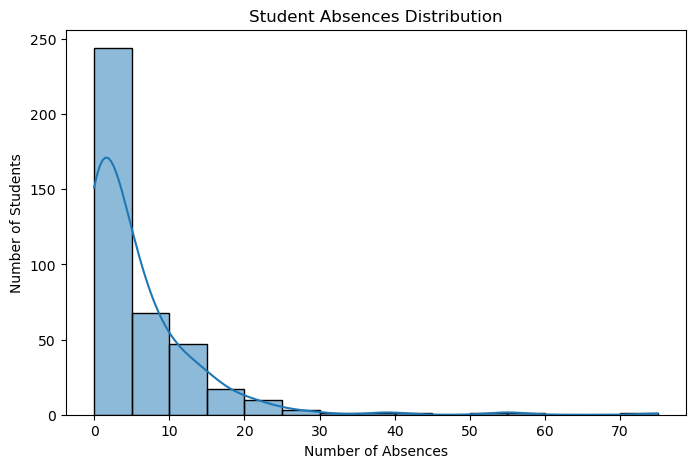

In [25]:
#Attendance analysis
plt.figure(figsize=(8, 5))

sns.histplot(df["absences"], bins=15, kde=True)

plt.title("Student Absences Distribution")
plt.xlabel("Number of Absences")
plt.ylabel("Number of Students")

plt.show()

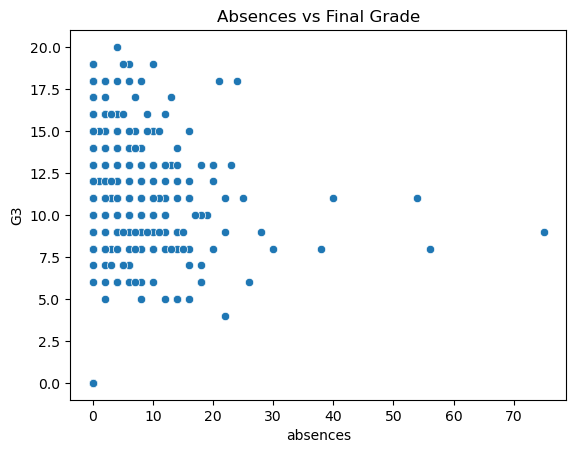

In [26]:
sns.scatterplot(
    data=df,
    x="absences",
    y="G3"
)

plt.title("Absences vs Final Grade")
plt.show()

Average First Period Grade: 10.90886075949367
Average Second Period Grade: 10.713924050632912
Average Final Grade: 10.415189873417722


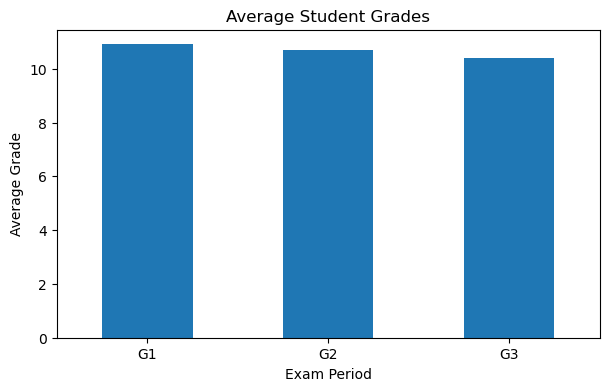

In [27]:
#Subject-wise performance analysis
print("Average First Period Grade:", df["G1"].mean())
print("Average Second Period Grade:", df["G2"].mean())
print("Average Final Grade:", df["G3"].mean())

grades = ["G1", "G2", "G3"]
average_grades = df[grades].mean()

average_grades.plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Average Student Grades")
plt.xlabel("Exam Period")
plt.ylabel("Average Grade")
plt.xticks(rotation=0)
plt.show()

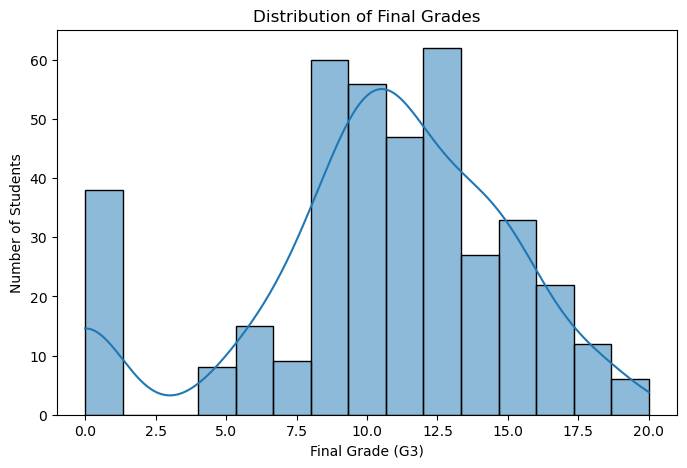

In [28]:
#Student performance visualizations
plt.figure(figsize=(8, 5))

sns.histplot(df["G3"], bins=15, kde=True)

plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")

plt.show()

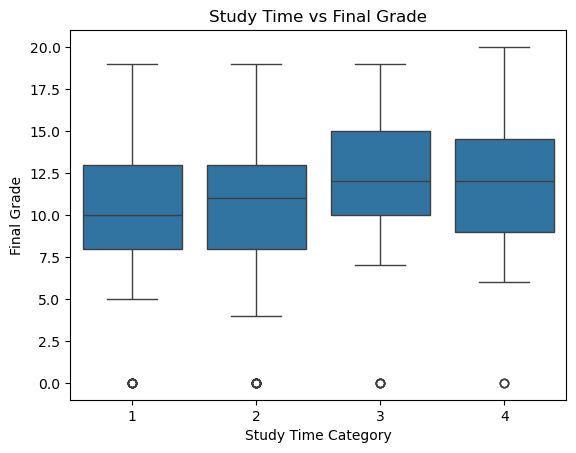

In [29]:
sns.boxplot(
    data=df,
    x="studytime",
    y="G3"
)

plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time Category")
plt.ylabel("Final Grade")

plt.show()

In [30]:
#Feature engineering
def classify_performance(grade):
    if grade >= 15:
        return "High"
    elif grade >= 10:
        return "Medium"
    else:
        return "Low"

df["Performance_Level"] = df["G3"].apply(
    classify_performance
)

print(df[["G3", "Performance_Level"]].head(10))

print(df["Performance_Level"].value_counts())

   G3 Performance_Level
0   6               Low
1   6               Low
2  10            Medium
3  15              High
4  10            Medium
5  15              High
6  11            Medium
7   6               Low
8  19              High
9  15              High
Performance_Level
Medium    192
Low       130
High       73
Name: count, dtype: int64


In [31]:
#Build a prediction model
# Select input features
X = df.drop(
    columns=["G3", "Performance_Level"]
)

# Convert categorical columns to numeric
X = pd.get_dummies(X, drop_first=True)

# Target variable
y = df["G3"]

# Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

print("Model training completed!")

Model training completed!


In [32]:
#Model evaluation
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", round(mae, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 2))

Mean Absolute Error: 1.65
Root Mean Squared Error: 2.38
R2 Score: 0.72


In [33]:
#Predict a student's performance
results = pd.DataFrame({
    "Actual Grade": y_test.values,
    "Predicted Grade": np.round(y_pred, 2)
})

print(results.head(10))

   Actual Grade  Predicted Grade
0            10             6.00
1            12            11.53
2             5             2.87
3            10             8.80
4             9             8.55
5            13            11.89
6            18            19.10
7             6             7.17
8             0             7.41
9            14            12.31
